# Comprehensive Global Stock Market Research
## Factor-Based Analysis Across 5 Major Markets

**Markets Covered**: China, Europe, Japan, Korea, United States

**Analysis Components**
1. Factor Performance Analysis
2. Sector Analysis
3. Cross-Country Comparison
4. Market Interpretation & Insights

---
## Setup and Data Loading

In [1]:
import configparser

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

from openai import http_client

warnings.filterwarnings('ignore')

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

# Color palette for countries
COUNTRY_COLORS = {
    'china': '#E63946',
    'europe': '#457B9D',
    'japan': '#2A9D8F',
    'korea': '#E9C46A',
    'us': '#264653'
}

# Factor colors
FACTOR_COLORS = {
    'BM': '#E63946',
    'HML': '#F4A261',
    'SMB': '#2A9D8F',
    'MOM': '#264653',
    'OP': '#8338EC',
    'INV': '#06D6A0',
    'REV': '#118AB2'
}

# Base path
BASE_PATH = Path('.')
COUNTRIES = ['us', 'europe', 'japan', 'china', 'korea']

print("Setup complete. Loading data...")

Setup complete. Loading data...


In [2]:
# GICS Sector mapping
SECTOR_NAMES = {
    '10': 'Energy',
    '15': 'Materials',
    '20': 'Industrials',
    '25': 'Consumer Disc.',
    '30': 'Consumer Staples',
    '35': 'Health Care',
    '40': 'Financials',
    '45': 'Info Tech',
    '50': 'Comm. Services',
    '55': 'Utilities',
    '60': 'Real Estate'
}

In [3]:
# Data containers
data = {
    'total_ER': {}, # whole univers's equity expected returns
    'beta': {}, # whole universe's equity factor exposure
    'factor_hs': {}, # historical factor returns
    'factor_hs_clipped': {}, # clipped historical factor returns(recent 52 weeks, normalized to 100)
    'factor_ts': {}, # historical factor expected returns
    'factor_ts_clipped': {}, # clipped historical factor expected returns(recent 52 weeks, normalized to 100)
    'index_ts': {}, # historical index expected returns
    'index_ts_clipped': {}, # clipped historical index expected returns(recent 52 weeks, normalized to 100)
    'sector_ts': {}, # historical sector expected returns
    'sector_ts_clipped': {}, # clipped historical sector expected returns(recent 52 weeks, normalized to 100)
    'industry_ts' : {}, # historical industry expected returns
    'industry_ts_clipped': {}, # clipped historical industry expected returns(recent 52 weeks, normalized to 100)
    'factor_ER': {}, # factor expected returns for most recent month
    'index_ER': {}, # index expected returns for most recent month
    'sector_ER': {}, # sector expected returns for most recent month
    'industry_ER': {}, # industry expected returns for most recent month
    'size_ER': {}, # size quintile expected returns for most recent month
    'top_bot': {}, # top and bottom 10 stocks by expected return
}

def clip_ts(df, periods=52):
    """Clip time series to the last 'periods' entries and normalize to 100"""
    clipped = df[-periods:]
    clipped = (clipped / clipped.iloc[0]) * 100
    return clipped

# Load all data
for country in COUNTRIES:
    country_path = BASE_PATH / country

    # Load each file type
    data['total_ER'][country] = pd.read_csv(country_path / 'total_ER.csv', index_col=0, dtype={'sector':str})
    data['beta'][country] = pd.read_csv(country_path / 'beta.csv', index_col=0, dtype={'sector':str, 'industry':str})

    # historical time series of factor index
    data['factor_hs'][country] = pd.read_csv(country_path / 'factor_hs.csv', index_col=0, parse_dates=True)
    data['factor_hs_clipped'][country] = clip_ts(data['factor_hs'][country])
    # time series of factor index's expected return index
    data['factor_ts'][country] = pd.read_csv(country_path / 'factor_ts.csv', index_col=0, parse_dates=True)
    data['factor_ts_clipped'][country] = clip_ts(data['factor_ts'][country])
    # time series of country index's expected return index
    data['index_ts'][country] = pd.read_csv(country_path / 'index_ts.csv', index_col=0, parse_dates=True)
    data['index_ts_clipped'][country] = clip_ts(data['index_ts'][country])
    # time series of sector index's expected return index
    data['sector_ts'][country] = pd.read_csv(country_path / 'sector_ts.csv', index_col=0, parse_dates=True)
    data['sector_ts_clipped'][country] = clip_ts(data['sector_ts'][country])
    # time series of industry index's expected return index
    data['industry_ts'][country] = pd.read_csv(country_path / 'industry_ts.csv', index_col=0, parse_dates=True)
    data['industry_ts_clipped'][country] = clip_ts(data['industry_ts'][country])

    data['factor_ER'][country] = pd.read_csv(country_path / 'factor_ER.csv')
    data['index_ER'][country] = pd.read_csv(country_path / 'index_ER.csv')
    data['sector_ER'][country] = pd.read_csv(country_path / 'sector_ER.csv', dtype={'sector':str})
    data['industry_ER'][country] = pd.read_csv(country_path / 'industry_ER.csv', dtype={'industry':str})

    data['size_ER'][country] = pd.read_csv(country_path / 'size_ER.csv')
    data['top_bot'][country] = pd.read_csv(country_path / 'ERtop+bot10.csv', dtype={'sector':str})

print("Data loaded successfully!")
print(f"\nCountries: {COUNTRIES}")
print(f"\nStock counts by market:")
for country in COUNTRIES:
    print(f"  {country.upper()}: {len(data['total_ER'][country]):,} stocks")

Data loaded successfully!

Countries: ['us', 'europe', 'japan', 'china', 'korea']

Stock counts by market:
  US: 2,939 stocks
  EUROPE: 599 stocks
  JAPAN: 496 stocks
  CHINA: 575 stocks
  KOREA: 296 stocks


In [4]:
data['factor_hs_clipped']['korea'].to_clipboard()

In [4]:
# NORMALIZATION FUNCTIONS FOR CROSS-COUNTRY COMPARISON
# Since factor models have different scales across countries, we need to
# normalize values before making cross-country comparisons.

def zscore_normalize(series):
    """Convert to z-scores (mean=0, std=1)"""
    return (series - series.mean()) / series.std()

def normalize(er, ts, er_ind:str, er_col:str, ts_col:str=None):
    """Normalize ER values using z-score based on time series data"""
    er_with_index = er.set_index(er_ind, inplace=False)
    er_val = er_with_index[er_col] / 100
    if ts_col is not None:
        ts_er = ts.filter(like=ts_col, axis=1)
        ts_er.columns = ts_er.columns.str.replace(ts_col, '')
    else:
        ts_er = ts
    ts_mean = ts_er.mean()
    ts_std = ts_er.std()

    data = pd.concat([er_val, ts_mean, ts_std], axis=1)
    data.columns = ['ER', 'Mean', 'Std']
    zscore = (data['ER'] - data['Mean']) / data['Std']
    zscore.name = 'ER_zscore'
    result = pd.concat([er_with_index, zscore], axis=1).dropna()

    return result

# Create normalized versions of key data
print("\n" + "="*70)
print("CREATING NORMALIZED DATA FOR CROSS-COUNTRY COMPARISON")
print("="*70)

# Normalize ER data for each country
for country in COUNTRIES:
    # Normalize equity ERs
    total_er = data['total_ER'][country].copy()
    if 'ER' in total_er.columns:
        total_er['ER_zscore'] = zscore_normalize(total_er['ER'])
    data['total_ER'][country] = total_er

    # Normalize index ERs
    er = data['index_ER'][country].copy()
    ts = data['index_ts'][country].copy()

    data['index_ER'][country] = normalize(er, ts, 'index', 'wER', '_ER')

    # Normalize sector ERs
    er = data['sector_ER'][country].copy()
    ts = data['sector_ts'][country].copy()

    data['sector_ER'][country] = normalize(er, ts, 'sector', 'wER', '_ER')

    # Normalize industry ERs
    er = data['industry_ER'][country].copy()
    ts = data['industry_ts'][country].copy()

    data['industry_ER'][country] = normalize(er, ts, 'industry', 'wER', '_ER')

    # Normalize factor returns (relative strength within country)
    er = data['factor_ER'][country].copy()
    ts = data['factor_ts'][country].copy()
    data['factor_ER'][country] = normalize(er, ts, 'factor', 'ER', '_ER')

print("Normalization methods applied:")
print("  • Z-Score: Standardized (mean=0, std=1) - good for relative comparisons")
print("  • Note: Use normalized values for cross-country comparisons")


CREATING NORMALIZED DATA FOR CROSS-COUNTRY COMPARISON
Normalization methods applied:
  • Z-Score: Standardized (mean=0, std=1) - good for relative comparisons
  • Note: Use normalized values for cross-country comparisons


In [ ]:
# ============================================================
# LLM Commentary Helper  (web search + persistent conversation)
# Requires: pip install openai
# Set environment variable: OPENAI_API_KEY=your-key
# ============================================================
import os
import datetime
from IPython.display import display, Markdown

OPENAI_MODEL = "gpt-5-mini"  # change to "gpt-4o" for higher quality

_conversation_history = []

_SYSTEM_MESSAGE = {
    "role": "system",
    "content": (
        "당신은 글로벌 대형 기관투자자를 대상으로 미국, 유럽, 일본, 중국, 한국 시장의 "
        "멀티팩터 포트폴리오 전략을 수립하는 '뉴스 통합형 시니어 퀀트 전략가(News-Integrated Chief Quant Strategist)'입니다.\n\n"
        "【핵심 분석 원칙】\n"
        "1. 최신 뉴스 우선: 반드시 현재 날짜 기준 최근 2~4주 이내의 실제 시장 뉴스, 거시경제 이벤트, 정책 발표, 기업 공시를 먼저 검색하고 이를 분석의 중심으로 삼으십시오.\n"
        "2. 팩터 데이터는 보조 근거: 제공된 Z-스코어, 방향성(상승/하락) 등 팩터 데이터는 뉴스 해석을 뒷받침하는 정량적 확인 도구로만 활용하십시오. 수치를 직접 나열하는 것을 금지합니다.\n"
        "3. 이벤트-드리븐 내러티브: 모든 분석은 '어떤 사건/정책/테마가 이 팩터·섹터·종목을 움직이는가'라는 질문에 답하는 형식으로 서술하십시오.\n"
        "4. Bottom-line Up Front: 가장 중요한 뉴스 기반 투자 시그널부터 시작하고, 수치는 괄호 안에 간략히 표기하십시오.\n"
        "5. 격식체 한국어: 투자위원회(IC) 제출용 보고서에 부합하는 명사형 어미(~함, ~임, ~판단, ~권고)를 사용하십시오.\n"
        "6. 최신성 보장: 검색 시 반드시 현재 연도·월을 포함한 쿼리를 사용하여 최신 뉴스만 인용하십시오."
    )
}

def reset_conversation():
    global _conversation_history
    _conversation_history = []
    print("대화 기록이 초기화되었습니다.")

def llm_explain(data_str: str, prompt: str, use_search: bool = True) -> str:
    global _conversation_history
    try:
        from openai import OpenAI
        import httpx
        key = os.getenv('OPENAI_API_KEY', '')
        if not key:
            return "_LLM 해설을 사용할 수 없습니다 — `OPENAI_API_KEY` 환경 변수를 설정하세요._"

        client = OpenAI(api_key=key, http_client=httpx.Client(verify=False))
        today = datetime.date.today().isoformat()
        date_preamble = f"[오늘 날짜: {today}. 최근 2~4주 이내의 최신 뉴스를 검색하여 분석에 활용하십시오.]\n\n"
        user_message = {
            "role": "user",
            "content": date_preamble + prompt + "\n\nData:\n" + data_str
        }
        messages = [_SYSTEM_MESSAGE] + _conversation_history + [user_message]
        kwargs = dict(model=OPENAI_MODEL, input=messages)
        if use_search:
            kwargs["tools"] = [{"type": "web_search_preview"}]
        response = client.responses.create(**kwargs)
        reply = response.output_text
        _conversation_history.append(user_message)
        _conversation_history.append({"role": "assistant", "content": reply})
        return reply
    except ImportError:
        return "_`openai` 패키지가 설치되지 않았습니다 — `pip install openai`를 실행하세요._"
    except Exception as e:
        return f"_LLM 오류: {e}_"

def show_explanation(data_str: str, prompt: str, title: str = "분석 해설", use_search: bool = True):
    text = llm_explain(data_str, prompt, use_search=use_search)
    display(Markdown(f"---\n### 💬 {title}\n\n{text}\n\n---"))

reset_conversation()
print(f"LLM 헬퍼 로드 완료. 모델: {OPENAI_MODEL}")
print("대화 메모리: 활성화 (초기화하려면 reset_conversation() 호출)")
print("웹 검색: 활성화 (최신 뉴스 기반 분석)")
print("API 키:", "✓ 설정됨" if os.getenv('OPENAI_API_KEY') else "✗ 미설정 (OPENAI_API_KEY 환경 변수를 설정하세요)")

---
## Historical Analysis

### Factor Time Series Performance

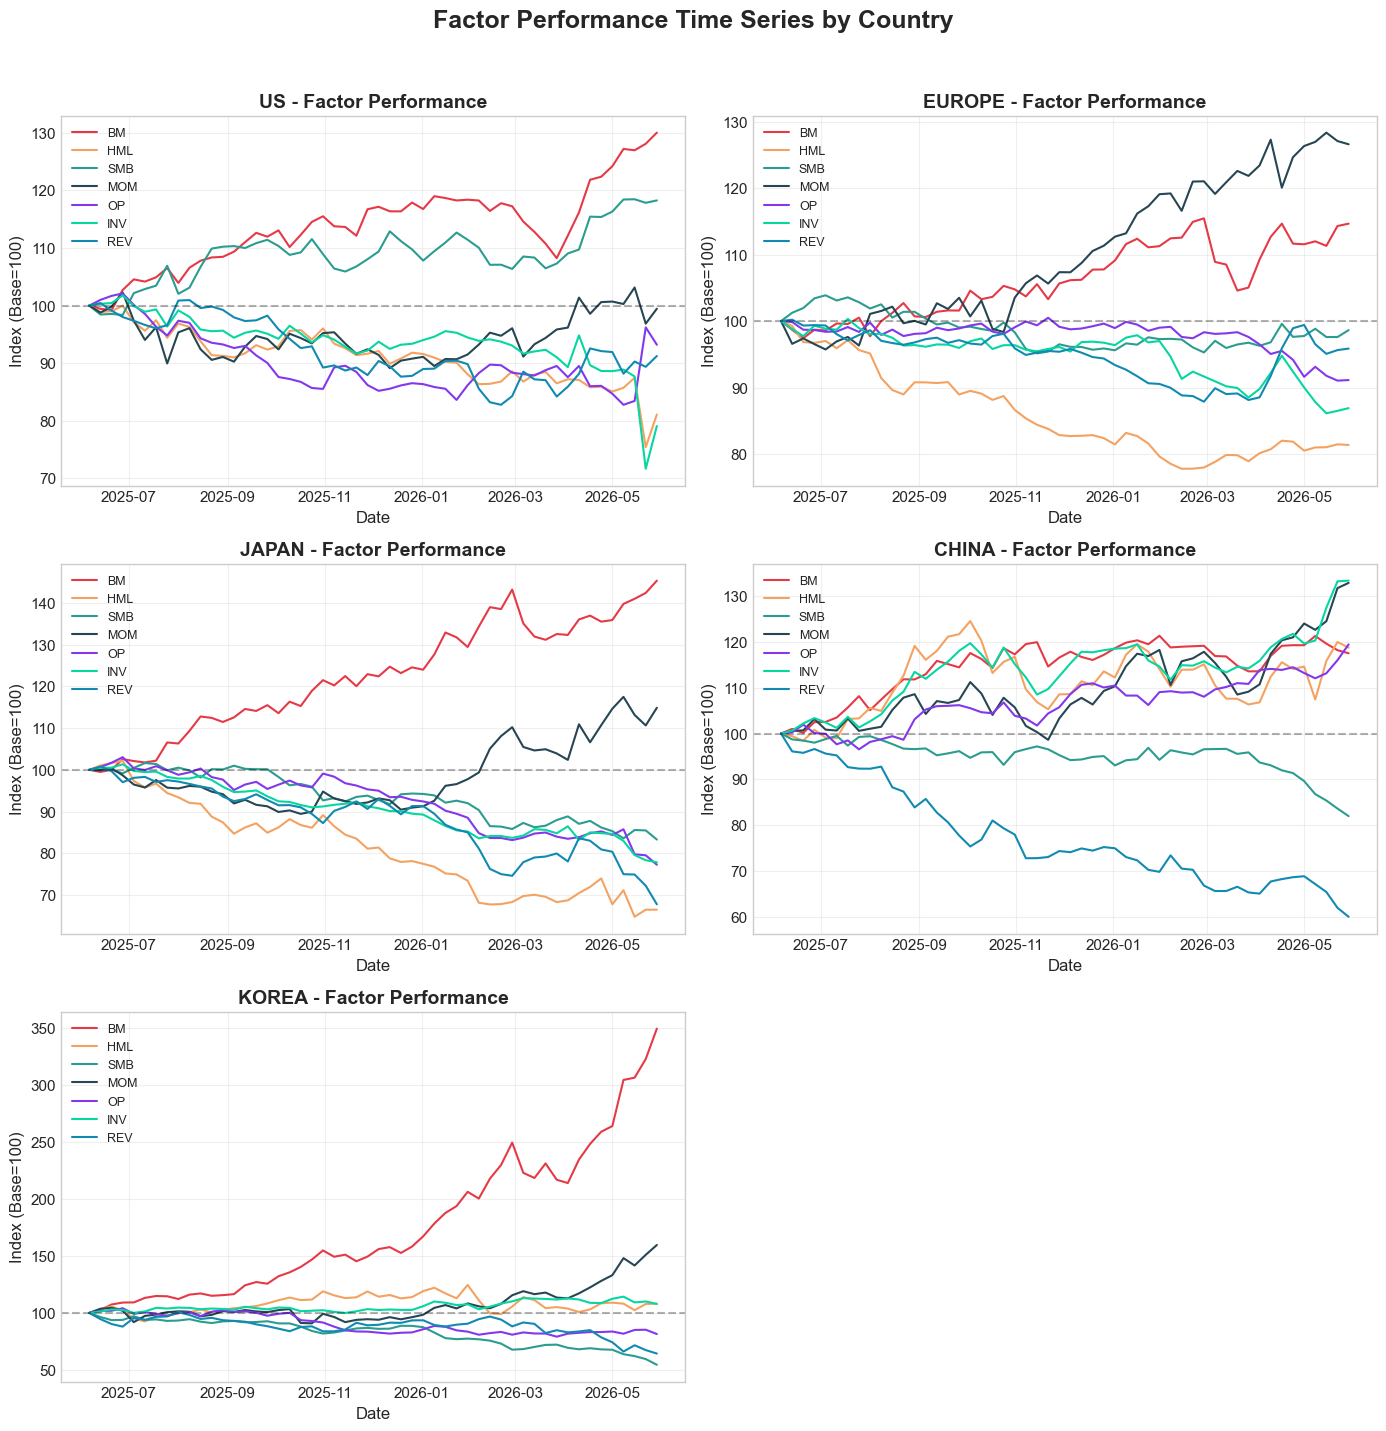

In [6]:
# Plot factor time series for each country
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for idx, country in enumerate(COUNTRIES):
    ax = axes[idx]
    factor_ts = data['factor_hs_clipped'][country]

    for col in factor_ts.columns:
        if col in FACTOR_COLORS:
            ax.plot(factor_ts.index, factor_ts[col], label=col,
                   color=FACTOR_COLORS.get(col, 'gray'), linewidth=1.5)

    ax.axhline(y=100, color='black', linestyle='--', alpha=0.3)
    ax.set_title(f'{country.upper()} - Factor Performance', fontsize=14, fontweight='bold')
    ax.set_xlabel('Date')
    ax.set_ylabel('Index (Base=100)')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3)

# Hide the 6th subplot
axes[5].axis('off')

plt.suptitle('Factor Performance Time Series by Country', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [7]:
# Calculate factor statistics
def calculate_factor_stats(factor_ts):
    """Calculate comprehensive factor statistics"""
    returns = factor_ts.pct_change().dropna()

    stats = pd.DataFrame({
        'Total Return (%)': ((factor_ts.iloc[-1] / factor_ts.iloc[0]) - 1) * 100,
        'Ann. Return (%)': returns.mean() * 52 * 100,
        'Ann. Vol (%)': returns.std() * np.sqrt(52) * 100,
        'Sharpe Ratio': (returns.mean() * 52) / (returns.std() * np.sqrt(52)),
        'Max Drawdown (%)': ((factor_ts / factor_ts.cummax()) - 1).min() * 100,
        'Skewness': returns.skew(),
        'Kurtosis': returns.kurtosis()
    })
    return stats.round(3)

# Display factor stats for each country
for country in COUNTRIES:
    print(f"\n{'='*70}")
    print(f"{country.upper()} - FACTOR STATISTICS")
    print("="*70)
    stats = calculate_factor_stats(data['factor_hs_clipped'][country])
    display(stats.style.format('{:.1f}').background_gradient(cmap='RdYlGn', subset=['Sharpe Ratio'], axis=0))


US - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,30.0,27.6,12.5,2.2,-9.0,0.3,-0.1
HML,-18.9,-19.4,19.3,-1.0,-24.6,-2.0,13.0
SMB,18.3,18.0,13.1,1.4,-5.8,0.2,0.7
MOM,-0.5,1.2,18.9,0.1,-12.8,-0.4,0.5
OP,-6.8,-5.3,19.9,-0.3,-18.9,3.6,19.2
INV,-20.9,-20.8,24.4,-0.9,-29.6,-2.3,17.2
REV,-8.8,-8.2,14.9,-0.6,-18.0,0.4,0.8



EUROPE - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,14.6,14.8,12.8,1.2,-9.4,-0.8,1.7
HML,-18.6,-20.6,8.8,-2.3,-22.2,-0.2,0.3
SMB,-1.4,-1.1,7.4,-0.2,-8.4,0.1,0.5
MOM,26.6,25.2,15.2,1.7,-5.7,-0.4,1.0
OP,-8.9,-9.3,6.6,-1.4,-9.4,-0.4,-0.0
INV,-13.1,-13.9,9.4,-1.5,-14.1,-0.0,0.4
REV,-4.1,-3.9,9.6,-0.4,-12.3,1.3,3.3



JAPAN - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,45.4,39.3,14.3,2.7,-8.4,-0.4,0.7
HML,-33.5,-39.5,19.7,-2.0,-36.6,-0.9,1.8
SMB,-16.7,-18.1,10.2,-1.8,-18.0,-0.3,0.3
MOM,14.9,15.7,17.8,0.9,-10.9,0.9,1.4
OP,-22.8,-25.6,11.8,-2.2,-25.0,-1.2,4.3
INV,-22.2,-25.1,8.5,-3.0,-23.2,-0.5,1.9
REV,-32.2,-38.0,17.7,-2.1,-32.8,0.2,2.0



CHINA - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,17.5,17.1,11.9,1.4,-6.4,-0.3,0.1
HML,18.7,19.9,22.0,0.9,-15.4,-0.1,-0.0
SMB,-18.0,-19.7,10.0,-2.0,-18.0,0.2,-0.1
MOM,32.8,30.9,19.5,1.6,-11.3,-0.3,-0.1
OP,19.4,18.7,11.1,1.7,-5.3,0.3,-0.1
INV,33.3,30.5,14.9,2.0,-9.4,0.1,-0.2
REV,-39.9,-50.1,18.0,-2.8,-39.9,0.3,0.4



KOREA - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,249.3,134.0,31.8,4.2,-14.2,-0.2,1.4
HML,8.1,12.5,30.4,0.4,-20.5,-0.3,0.7
SMB,-45.5,-59.6,19.2,-3.1,-45.5,-0.6,0.2
MOM,59.6,52.4,30.3,1.7,-13.0,-0.5,1.5
OP,-18.5,-19.3,17.5,-1.1,-24.0,-0.2,-0.4
INV,7.9,8.6,13.2,0.6,-6.2,-0.2,0.0
REV,-35.6,-40.5,29.4,-1.4,-36.1,0.0,0.3


### Factor Correlation Analysis

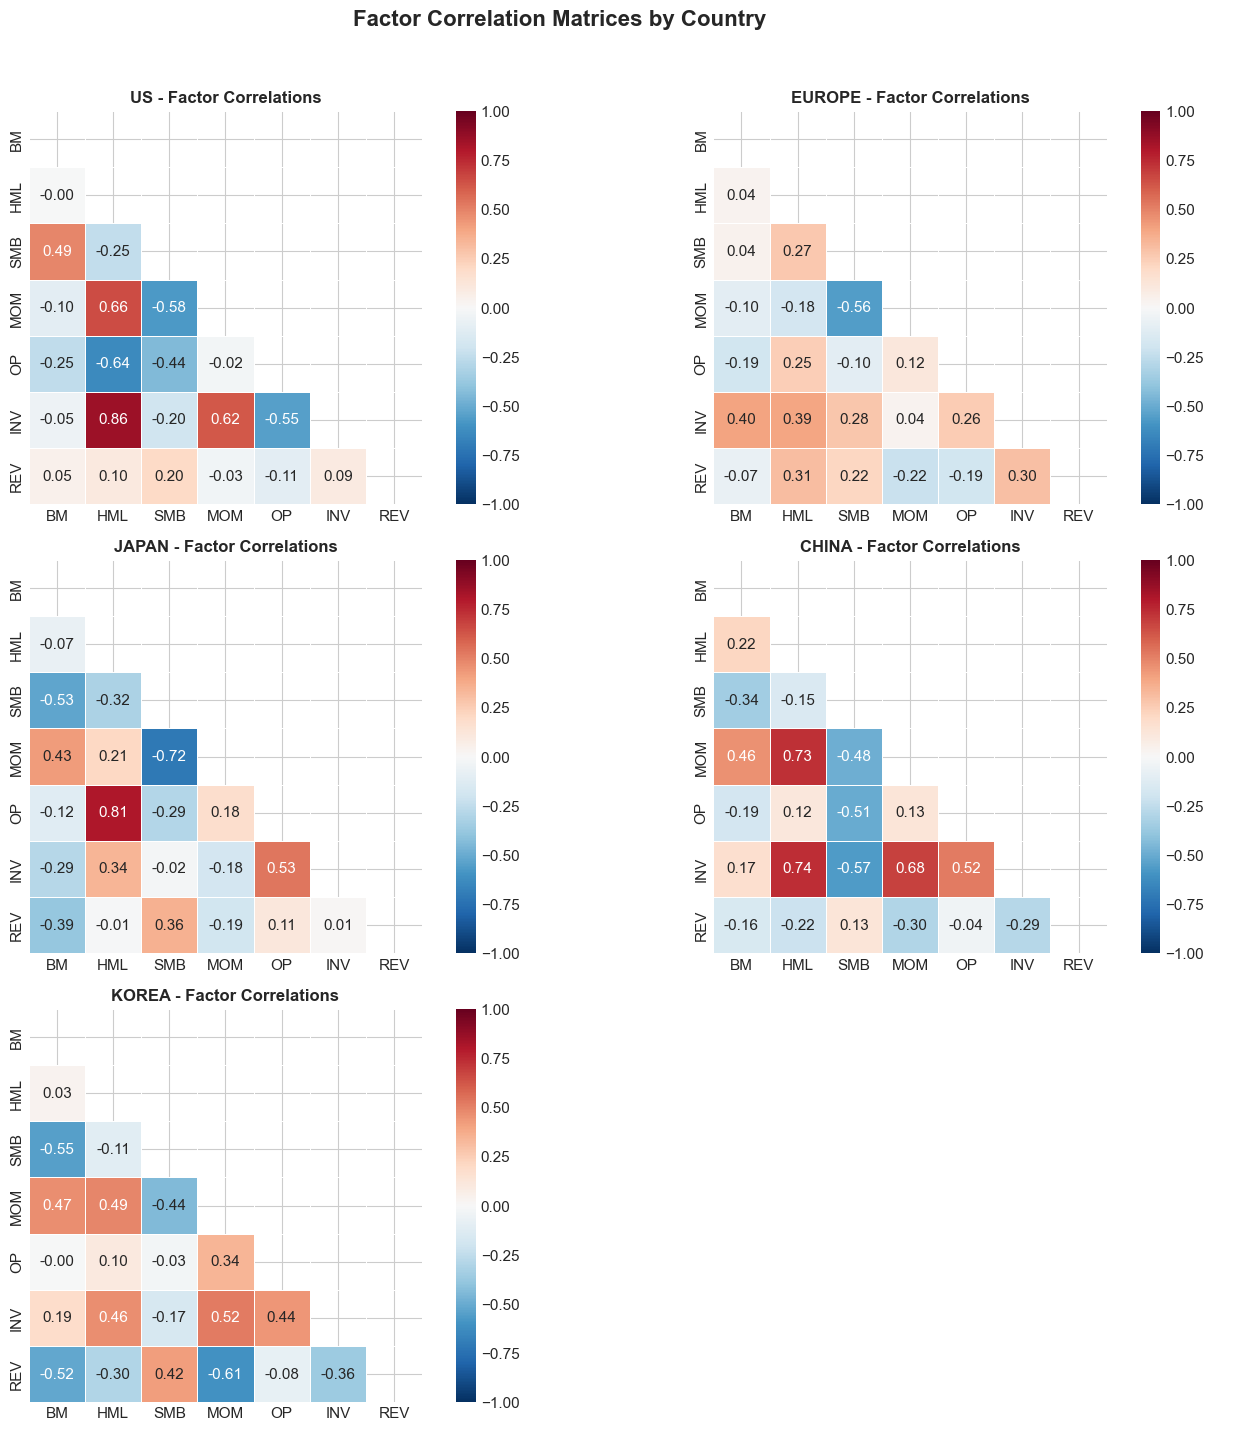

In [8]:
# Factor correlation matrices
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for idx, country in enumerate(COUNTRIES):
    ax = axes[idx]
    factor_returns = data['factor_hs_clipped'][country].pct_change().dropna()
    corr = factor_returns.corr()

    mask = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
                center=0, ax=ax, vmin=-1, vmax=1,
                square=True, linewidths=0.5)
    ax.set_title(f'{country.upper()} - Factor Correlations', fontsize=12, fontweight='bold')

axes[5].axis('off')
plt.suptitle('Factor Correlation Matrices by Country', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
# === LLM Commentary: Historical Analysis (News-Driven) ===
_hist_txt = f"HISTORICAL ANALYSIS — Factor Direction Summary (week ending approx. {datetime.date.today().isoformat()})\n\n"

for _c in COUNTRIES:
    _hs = data['factor_hs_clipped'][_c]
    _ret4  = (_hs.iloc[-1] / _hs.iloc[-5]  - 1) * 100 if len(_hs) >= 5 else pd.Series(dtype=float)
    _prior4 = (_hs.iloc[-5] / _hs.iloc[-9] - 1) * 100 if len(_hs) >= 9 else pd.Series(dtype=float)
    _accel = (_ret4 - _prior4).dropna().sort_values(ascending=False)
    _top3 = list(_accel.head(3).index)
    _bot3 = list(_accel.tail(3).index)
    _hist_txt += f"{_c.upper()}: 가속 팩터={', '.join(_top3)} | 감속 팩터={', '.join(_bot3)}\n"

_hist_prompt = (
    "당신은 글로벌 퀀트 전략가입니다. 제공된 국가별 팩터 가속/감속 방향 요약을 바탕으로 각 시장의 최신 거시경제 뉴스를 검색하십시오.\n\n"
    "검색 지시: 각 국가별로 '[국가명] stock market factor style rotation news [현재연월]', '[국가명] 금리 통화정책 최신 뉴스' 쿼리로 최신 이벤트를 검색하십시오.\n\n"
    "출력 구조:\n"
    "1. 핵심 뉴스 드라이버 (국가별): 각 시장에서 팩터 흐름을 주도하는 실제 이벤트/정책/테마를 뉴스 기반으로 서술. 팩터 방향은 괄호 안에 간략 표기.\n"
    "2. 글로벌 공통 테마: 여러 시장에서 동시에 관찰되는 스타일 로테이션의 배경 이벤트.\n"
    "3. 단기 투자 시그널: 뉴스 흐름상 향후 2~4주 주목할 국가/팩터 조합 2~3개.\n\n"
    "분량: A4 0.5페이지 이내. 수치 나열 금지. 뉴스 내러티브 우선."
)

show_explanation(_hist_txt, _hist_prompt, title="1.3 Historical Analysis: 뉴스 기반 팩터 동인 분석")

---
## Stock Market(Country) Analysis

### Market Expected Returns

MARKET-LEVEL ANALYSIS

⚠️  IMPORTANT: Market ER values are NOT directly comparable across countries
    because factor models have different scales/calibrations.

[1] MARKET ER - (z-score scales)
----------------------------------------------------------------------


,Weighted Mean ER (%)
US,-0.06
EUROPE,-0.47
JAPAN,0.19
CHINA,-1.23
KOREA,1.30



[2] CROSS-COUNTRY COMPARABLE METRICS
----------------------------------------------------------------------


,Market ER Percentile,Market ER Z-Score,% Stocks Positive ER,ER Dispersion (Q80-Q20),ER Sharpe (mean/std)
Country,,,,,
US,41.1,-0.06,55.1%,3.17,0.02
EUROPE,25.8,-0.47,43.1%,1.90,-0.02
JAPAN,54.2,0.19,92.9%,1.53,0.12
CHINA,16.7,-1.23,36.9%,1.75,-0.04
KOREA,91.6,1.30,94.3%,2.92,0.14



Interpretation Guide:
  • Market ER Percentile: Higher = More strong signal for the market relative to historical periods
  • % Stocks Positive ER: Higher = More bullish signal for the market
  • ER Sharpe: Higher = More consistent positive signal across stocks


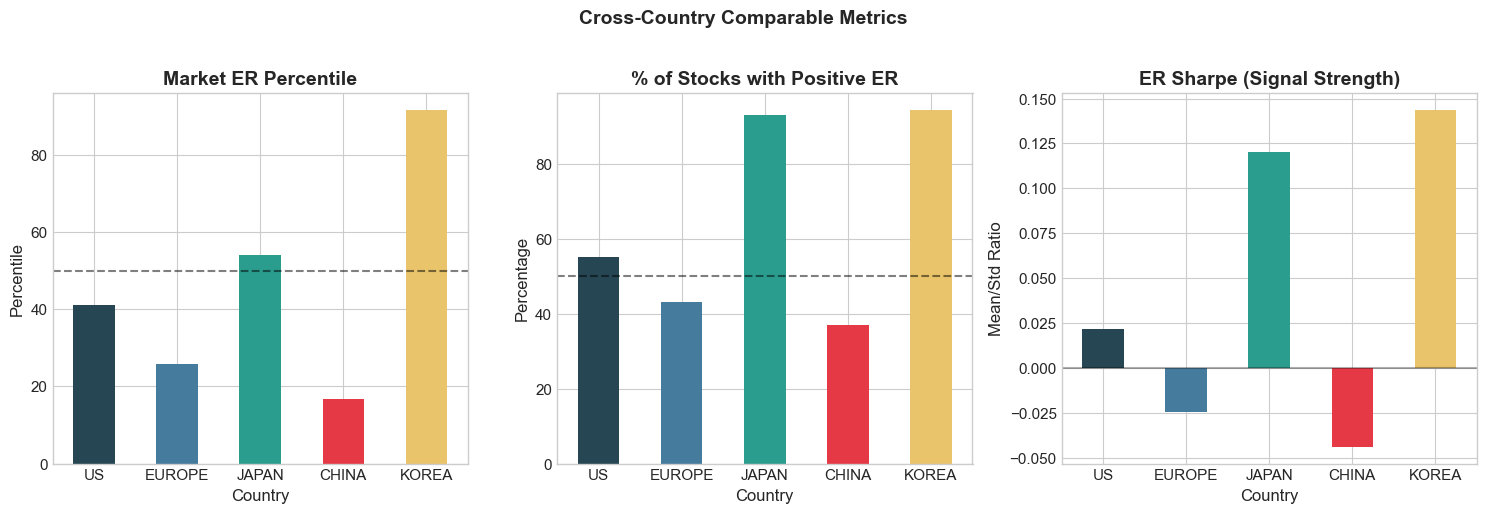

In [10]:
# Market-level expected returns comparison - WITH NORMALIZATION CONTEXT
print("="*70)
print("MARKET-LEVEL ANALYSIS")
print("="*70)
print("\n⚠️  IMPORTANT: Market ER values are NOT directly comparable across countries")
print("    because factor models have different scales/calibrations.\n")

# Raw market ERs
market_er = {}
for country in COUNTRIES:
    wmean = data['index_ER'][country]['ER_zscore'].iloc[0]
    market_er[country.upper()] = wmean

market_er_df = pd.DataFrame([market_er], index=['Weighted Mean ER (%)']).T

print("[1] MARKET ER - (z-score scales)")
print("-"*70)
display(market_er_df.style.format('{:.2f}'))

# Calculate comparable metrics using within-country distribution
print("\n[2] CROSS-COUNTRY COMPARABLE METRICS")
print("-"*70)

comparable_metrics = []
for country in COUNTRIES:
    total_stock_er = data['total_ER'][country]
    index_total_history_er = data['index_ts'][country]['index_ER']
    index_er = data['index_ER'][country]['wER'].iloc[0]

    # What percentile is the market ER within its own distribution?
    market_percentile = (index_er/100 > index_total_history_er).mean() * 100

    # Z-score of market ER within country
    market_zscore = data['index_ER'][country]['ER_zscore'].iloc[0]

    # Stock-wise
    er_values = total_stock_er['ER'].dropna()
    sh_values = total_stock_er['Sharpe'].dropna()

    # Percentage of stocks with positive ER
    pct_positive = (er_values > 0).mean() * 100

    # Spread between top and bottom quintile
    er_spread = er_values.quantile(0.8) - er_values.quantile(0.2)

    # Sharpe-like metric: mean ER / std ER
    er_sharpe = sh_values.mean()

    comparable_metrics.append({
        'Country': country.upper(),
        'Market ER Percentile': market_percentile,
        'Market ER Z-Score': market_zscore,
        '% Stocks Positive ER': pct_positive,
        'ER Dispersion (Q80-Q20)': er_spread,
        'ER Sharpe (mean/std)': er_sharpe
    })

comparable_df = pd.DataFrame(comparable_metrics).set_index('Country')
display(comparable_df.style.format({
    'Market ER Percentile': '{:.1f}',
    'Market ER Z-Score': '{:.2f}',
    '% Stocks Positive ER': '{:.1f}%',
    'ER Dispersion (Q80-Q20)': '{:.2f}',
    'ER Sharpe (mean/std)': '{:.2f}'
}).background_gradient(cmap='RdYlGn', axis=0))

print("\nInterpretation Guide:")
print("  • Market ER Percentile: Higher = More strong signal for the market relative to historical periods")
print("  • % Stocks Positive ER: Higher = More bullish signal for the market")
print("  • ER Sharpe: Higher = More consistent positive signal across stocks")

# Bar chart of comparable metrics
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot 1: Market Percentile
ax = axes[0]
colors = [COUNTRY_COLORS[c.lower()] for c in comparable_df.index]
comparable_df['Market ER Percentile'].plot(kind='bar', ax=ax, color=colors)
ax.set_title('Market ER Percentile', fontweight='bold')
ax.set_ylabel('Percentile')
ax.axhline(y=50, color='black', linestyle='--', alpha=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

# Plot 2: % Positive ER
ax = axes[1]
comparable_df['% Stocks Positive ER'].plot(kind='bar', ax=ax, color=colors)
ax.set_title('% of Stocks with Positive ER', fontweight='bold')
ax.set_ylabel('Percentage')
ax.axhline(y=50, color='black', linestyle='--', alpha=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

# Plot 3: ER Sharpe
ax = axes[2]
comparable_df['ER Sharpe (mean/std)'].plot(kind='bar', ax=ax, color=colors)
ax.set_title('ER Sharpe (Signal Strength)', fontweight='bold')
ax.set_ylabel('Mean/Std Ratio')
ax.axhline(y=0, color='black', linestyle='-', alpha=0.3)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

plt.suptitle('Cross-Country Comparable Metrics', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [11]:
# === LLM Commentary: Stock Market Analysis ===
_market_txt = "STOCK MARKET (COUNTRY-LEVEL) ANALYSIS - Current + Recent Trend\n\n"

for _c in COUNTRIES:
    _total_er  = data['total_ER'][_c]
    _idx_ts    = data['index_ts'][_c]['index_ER']
    _idx_er    = data['index_ER'][_c]['wER'].iloc[0]
    _pctile    = (_idx_er / 100 > _idx_ts).mean() * 100
    _zscore    = data['index_ER'][_c]['ER_zscore'].iloc[0]
    _pct_pos   = (_total_er['ER'].dropna() > 0).mean() * 100
    _er_sharpe = _total_er['Sharpe'].dropna().mean()
    _z4w = float(_idx_ts.iloc[-5])  if len(_idx_ts) >= 5  else float('nan')
    _z8w = float(_idx_ts.iloc[-9])  if len(_idx_ts) >= 9  else float('nan')
    _cur = float(_idx_ts.iloc[-1])
    _chg4 = _cur - _z4w
    _chg8 = _cur - _z8w
    _trend = "IMPROVING" if _chg4 > 0 else "DETERIORATING"
    _market_txt += (
        f"{_c.upper()}: Percentile={_pctile:.1f}% | Z-Score={_zscore:+.2f} | "
        f"StocksPositiveER={_pct_pos:.1f}% | AvgSharpe={_er_sharpe:.3f}\n"
        f"         ER Trend: cur={_cur:.4f} | 4w-ago={_z4w:.4f} | 8w-ago={_z8w:.4f} "
        f"| 4w-chg={_chg4:+.4f} | 8w-chg={_chg8:+.4f} ↑ {_trend}\n\n"
    )

_market_prompt = (
"""[Role & Context]\n
당신은 글로벌 자산배분 전략가(Chief Investment Strategist)입니다. 기관 투자자 및 포트폴리오 매니저를 대상으로 시장 기대수익률(ER) 데이터를 해석하여 "1.4 Stock Market Analysis" 결론 브리핑을 작성합니다.\n
\n
[Writing Principles]\n
\n
Table & Bullet First: 텍스트를 나열하지 말고, 핵심 요약 표(Matrix)를 최상단에 배치한 후 세부 리스크를 서술하십시오.\n
\n
Actionable Jargon: 금융 전문 용어(Tactical Tilt, Divergence, Regime, Underweight 등)를 사용하여 문장을 최대한 압축하십시오. (~해석됨, ~전망됨 같은 모호한 어미 배제)\n
\n
Anomaly Focus: 모든 국가를 균등하게 서술하지 말고, 추세가 급변하거나(Momentum Pivot) 데이터 간 충돌(Divergence)이 있는 위험 국가 위주로 가중치를 두어 서술하십시오.\n
\n
[Output Structure]\n
\n
1. 글로벌 ER 모멘텀 및 전술적 자산배분 (TAA) 매트릭스\n
[5개 시장(한국, 중국, 미국, 일본, 유럽)의 현재 위치(Z-Score), 4w/8w 추세, 최종 배분 의견(OW/N/UW)을 한눈에 보는 표로 정리]\n
\n
2. 핵심 마켓 시그널 및 불일치(Divergence) 경고\n
모멘텀 극단 과열 지역: (예: 한국의 가속화 및 리스크 관리)\n
\n
가격-추세 불일치(Divergence) 지역: (예: 미국·일본의 절대 수준 대비 단기 둔화)\n
\n
바닥 통과(Bottoming) 지역: (예: 중국의 턴어라운드 진위 여부)\n
\n
3. 글로벌 동조화 진단 및 리스크 헤지 가이드\n
현재 글로벌 시장의 비동기화(De-synchronization) 특성과 포트폴리오 차원의 최종 방어 전략을 2~3줄로 요약."""
)

show_explanation(_market_txt, _market_prompt, title="1.4 Stock Market Analysis 종합 해설")


---
### 💬 1.4 Stock Market Analysis 종합 해설

시장 국면 정의(BUF): 한국 중심의 단기 과열(Momentum‑Pivot)과 타 지역의 비동기화(De‑synchronization)가 공존하는 ‘지역적 Risk‑On 집중 국면’임.

글로벌 ER 모멘텀 및 TAA 매트릭스
| 국가 | Z‑Score | 4w Δ | 8w Δ | 트렌드(요약) | TAA |
|---|---:|---:|---:|---|---:|
| 한국 | +1.30 | +0.0721 | +0.1004 | 급속 가속·단기 과열(Percentile 91.6%) | OW |
| 중국 | -1.23 | +0.0041 | +0.0111 | 저수준에서 점진 회복(바닥 의심, Percentile 16.7%) | N |
| 미국 | -0.06 | -0.0238 | +0.0083 | 단기 악화·모멘텀 약화(StocksPositiveER 55.1%) | UW |
| 일본 | +0.19 | -0.0179 | +0.0078 | 중립 수준이나 4주 모멘텀 둔화(높은 StocksPositiveER) | N |
| 유럽 | -0.47 | +0.0110 | +0.0059 | 구조적 저평가·단기 개선 신호(Percentile 25.8%) | N |

핵심 마켓 시그널 및 불일치(Divergence) 경고
- 모멘텀 극단 과열: 한국 — ER 4주·8주 동시 대폭 상승(4w +7.2ppt, 8w +10.0ppt)로 Tactical Tilt 허용하나 Crowding·회수 위험 높음. 트레이드 크기 제한·트레일스탑 필수 권고함.  
- 가격‑추세 불일치: 미국·일본 — 절대 ER 수준(특히 일본 높은 StocksPositiveER) 대비 4주 모멘텀 하락으로 Momentum Pivot 리스크 존재. 모멘텀 기반 롱 익스포저는 리스크컷 규칙 적용 권고함.  
- 바닥 통과 의심: 중국 — ER 반등 지속(8w +1.11ppt)이나 Percentile·Z‑Score 동반 저점으로 진위 확인 필요. 정책·유동성·온쇼어 자금흐름으로 확인될 때에만 점진적 진입 권고함.

글로벌 동조화 진단 및 리스크 헤지 가이드
- 현재 국지적 Decoupling 심화: 한국이 과열로 단일국 집중 리스크 확대, 기타 선진국은 비동기적 약화/회복 흐름 병재됨.  
- 방어 전략: 포트폴리오 레벨에서 (1) 총 유동성 헷지(현금·단기채) 비중 소폭 확대, (2) 한국 집중 노출은 옵션 기반 보호(풋 또는 콜스프레드) 및 트레일스탑 적용, (3) 중국은 확인 신호(정책·자금유입) 발생 시 점진적 진입으로 Tactical Entry 운용 권고함.

---

---
## Factor Analysis

### Factor Expected Returns

In [12]:
# Create factor returns comparison table - RAW and NORMALIZED
print("="*70)
print("FACTOR RETURNS BY COUNTRY")
print("="*70)
print("    Use Z-Score for valid cross-country comparisons.\n")

# Z-Score normalized (within each country)
factor_zscore_df = pd.DataFrame()
for country in COUNTRIES:
    fr = data['factor_ER'][country]['ER_zscore']
    factor_zscore_df[country.upper()] = fr
factor_zscore_df = factor_zscore_df.T

print("\n[2] Z-SCORE NORMALIZED - Comparable across countries (0 = country average)")
print("-"*70)
display(factor_zscore_df.style.format('{:.2f}').background_gradient(cmap='RdYlGn', axis=None))

# Cross-country factor comparison using z-scores
print("\n[4] CROSS-COUNTRY FACTOR STRENGTH (Z-Score Average)")
print("-"*70)
print("Which factors are consistently strong/weak across all markets:")
factor_strength = factor_zscore_df.mean().sort_values(ascending=False)
for factor, zscore in factor_strength.items():
    strength = "STRONG ↑" if zscore > 0.5 else ("WEAK ↓" if zscore < -0.5 else "NEUTRAL →")
    bar = "█" * int(abs(zscore) * 10)
    print(f"  {factor:5}: {zscore:+.2f} {strength} {bar}")

FACTOR RETURNS BY COUNTRY
    Use Z-Score for valid cross-country comparisons.


[2] Z-SCORE NORMALIZED - Comparable across countries (0 = country average)
----------------------------------------------------------------------


,BM,HML,INV,MOM,OP,SMB
US,-0.51,-1.27,-0.56,-2.26,0.99,0.71
EUROPE,-0.47,-0.63,-0.30,-2.68,-0.56,0.25
JAPAN,0.61,-1.68,-0.06,2.54,-2.34,-4.99
CHINA,-0.17,0.85,-0.71,1.94,-4.94,-4.55
KOREA,1.11,6.38,4.18,2.36,0.16,-5.93



[4] CROSS-COUNTRY FACTOR STRENGTH (Z-Score Average)
----------------------------------------------------------------------
Which factors are consistently strong/weak across all markets:
  HML  : +0.73 STRONG ↑ ███████
  INV  : +0.51 STRONG ↑ █████
  MOM  : +0.38 NEUTRAL → ███
  BM   : +0.11 NEUTRAL → █
  OP   : -1.34 WEAK ↓ █████████████
  SMB  : -2.90 WEAK ↓ █████████████████████████████


### Factor Premium Comparison

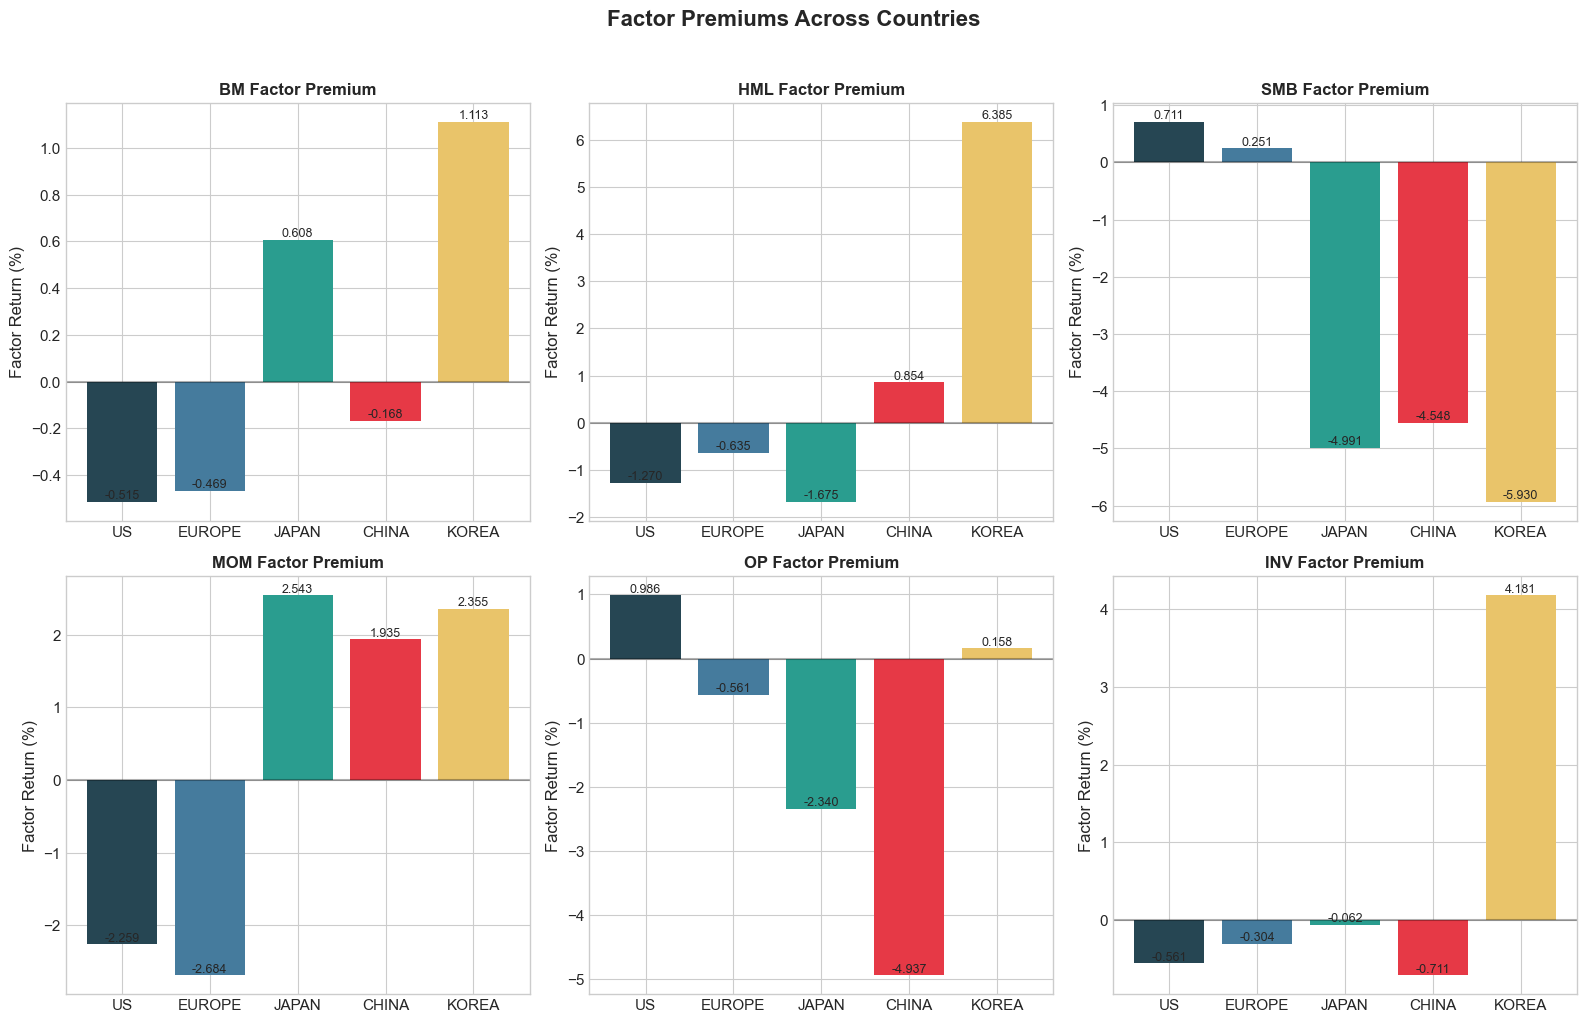

In [13]:
# Factor premium comparison across countries
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

factors = ['BM', 'HML', 'SMB', 'MOM', 'OP', 'INV']

for idx, factor in enumerate(factors):
    ax = axes[idx]
    factor_vals = []

    for country in COUNTRIES:
        fr = data['factor_ER'][country]['ER_zscore']
        if factor in fr.index:
            factor_vals.append(fr.loc[factor])
        else:
            factor_vals.append(0)

    colors = [COUNTRY_COLORS[c] for c in COUNTRIES]
    bars = ax.bar([c.upper() for c in COUNTRIES], factor_vals, color=colors)
    ax.axhline(y=0, color='black', linestyle='-', alpha=0.3)
    ax.set_title(f'{factor} Factor Premium', fontsize=12, fontweight='bold')
    ax.set_ylabel('Factor Return (%)')

    # Add value labels
    for bar, val in zip(bars, factor_vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
                f'{val:.3f}', ha='center', va='bottom', fontsize=9)

plt.suptitle('Factor Premiums Across Countries', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [14]:
# === LLM Commentary: Factor Analysis ===
_factor_a_txt = "FACTOR ANALYSIS \u2014 Expected Returns + Cross-Country Premiums\n\n"

# Part A: Factor ER (Z-score + 4w trend)
_factor_a_txt += "=== PART A: FACTOR EXPECTED RETURNS (Z-Score + 4-Week Trend) ===\n\n"
for _c in COUNTRIES:
    _fts   = data['factor_ts'][_c]
    _fER_z = data['factor_ER'][_c]['ER_zscore']
    _factor_a_txt += f"{'='*35}\n{_c.upper()}\n{'='*35}\n"
    _factor_a_txt += f"{'Factor':6} | Z-Score | cur ER  | 4w-ago  | 4w-chg | trend\n"
    for _f in _fER_z.index:
        _col = f"{_f}_ER"
        _z   = _fER_z.get(_f, float('nan'))
        if _col in _fts.columns and len(_fts) >= 5:
            _cur  = float(_fts[_col].iloc[-1])
            _4w   = float(_fts[_col].iloc[-5])
            _chg  = _cur - _4w
            _dir  = "↑" if _chg > 0 else "↓"
        else:
            _cur = _4w = _chg = float('nan')
            _dir = "?"
        _factor_a_txt += f"  {_f:5}: z={_z:+.2f} | {_cur:.4f} | {_4w:.4f} | {_chg:+.4f} {_dir}\n"
    _factor_a_txt += "\n"

# Global 4w average
_factor_a_txt += "GLOBAL 4-WEEK FACTOR ER CHANGE (avg across countries):\n"
_f_changes = {}
for _f in data['factor_ER'][COUNTRIES[0]]['ER_zscore'].index:
    _col = f"{_f}_ER"
    _chgs = []
    for _c in COUNTRIES:
        _fts = data['factor_ts'][_c]
        if _col in _fts.columns and len(_fts) >= 5:
            _chgs.append(float(_fts[_col].iloc[-1]) - float(_fts[_col].iloc[-5]))
    if _chgs:
        _f_changes[_f] = sum(_chgs) / len(_chgs)
for _f, _chg in sorted(_f_changes.items(), key=lambda x: -x[1]):
    _dir = "↑ RISING" if _chg > 0 else "↓ FALLING"
    _factor_a_txt += f"  {_f:5}: avg 4w-chg = {_chg:+.4f}  {_dir}\n"

# Part B: Cross-country factor premiums
_factor_a_txt += "\n=== PART B: CROSS-COUNTRY FACTOR PREMIUMS (Z-Score + 4-Week Direction) ===\n\n"
_factors_list = ['BM', 'HML', 'SMB', 'MOM', 'OP', 'INV']
for _f in _factors_list:
    _col = f"{_f}_ER"
    _factor_a_txt += f"{_f}:\n"
    for _c in COUNTRIES:
        _fts = data['factor_ts'][_c]
        _z   = data['factor_ER'][_c]['ER_zscore'].get(_f, float('nan'))
        if _col in _fts.columns and len(_fts) >= 5:
            _chg = float(_fts[_col].iloc[-1]) - float(_fts[_col].iloc[-5])
            _dir = "↑" if _chg > 0 else "↓"
        else:
            _chg, _dir = float('nan'), "?"
        _factor_a_txt += f"  {_c.upper():8}: z={_z:+.2f}  4w-chg={_chg:+.4f} {_dir}\n"
    _factor_a_txt += "\n"

_factor_prompt = (
"""[Role & Context]\n
당신은 글로벌 퀀트 전략가(Senior Quant Strategist)입니다. 기관 투자자를 대상으로 글로벌 팩터 데이터(Part A, B)를 분석하여, 향후 4주간 전술적 자산배분에 즉시 반영할 수 있는 **"1.5 Factor Analysis: 팩터 포지셔닝 매트릭스"**를 작성합니다.\n
\n
[Writing Principles]\n
\n
Bottom-line First (Table): 독자가 서론을 읽지 않도록, 최상단에 팩터별 글로벌 스탠스와 국가별 전술적 포지셔닝(OW/N/UW)을 정리한 표(Matrix)를 먼저 제시할 것.\n
\n
Signal over Background: 52주나 Z-스코어의 장기 맥락은 판단 근거로만 녹여내고, 텍스트는 **최근 4주간의 모멘텀 변화(가속/감속/반전)**에 집중하여 서술할 것.\n
\n
Actionable Conciseness: '해석됨', '시사함'과 같은 모호한 문장 미사여구를 배제하고, 금융 전문 용어(Crowding, Reversal, Alpha-Seeking, Tail Risk)를 사용하여 단도직입적으로 서술할 것.\n
\n
[Output Structure]\n
\n
1. 4주 팩터 포지셔닝 및 전술적 배분(TAA) 매트릭스\n
[팩터명 / 글로벌 스탠스(Long/Short/Neutral) / 최선호 국가(OW) / 회피 국가(UW) / 핵심 시그널(4w Chg 및 Z-score 요약)] 형태로 표 구성.\n
\n
2. 핵심 전술적 시그널 및 위험 경고 (Bullet Points)\n
글로벌 모멘텀 롱 (Global Momentum Long): 전 세계 공통으로 가장 강한 가속을 보이는 팩터와 포지셔닝 전략.\n
\n
포지션 혼잡 및 반전 경고 (Crowding & Reversal Alert): Z-스코어는 높으나 4주 모멘텀이 꺾인 시장/팩터 지적 및 리스크 관리법.\n
\n
국가 간 차별화 알파 (Cross-Border Alpha): 프리미엄 분산이 가장 큰 팩터를 활용한 최적의 [국가-팩터] 롱/숏 조합 3가지 이내 제시.\n
\n
3. 팩터 운용 가이드라인 (Risk Constraint)\n
포트폴리오 내 팩터 중복 리스크 및 포지션 한도 제약을 2~3줄로 명확히 권고."""
)

show_explanation(_factor_a_txt, _factor_prompt, title="1.5 Factor Analysis 종합 해설")


---
### 💬 1.5 Factor Analysis 종합 해설

Bottom‑line (BUF): 글로벌 4주 모멘텀은 Momentum·Beta 중심의 지역적 과열(특히 한국)과 SMB의 전역적 약화 동시 진행으로, 팩터별 전술적 선별(Long selective, Short broad SMB) 운용 권고됨.

팩터 포지셔닝 매트릭스
| 팩터 | 글로벌 스탠스 | 최선호 국가 (OW) | 회피 국가 (UW) | 핵심 시그널(4주 Δ / Z‑요약) |
|---|---:|---|---|---|
| MOM | Long | Korea, Japan, China | US, Europe | 글로벌 avg 4w +0.0157↑. Korea 4w +0.0583, z+2.36(가속) vs US z‑2.26(모멘텀 누수) |
| BM  | Neutral→Long | Korea, Europe | US | 글로벌 avg 4w +0.0084↑. Korea 4w +0.0689, z+1.11(리레이팅 아웃라이어); US 4w ‑0.0238(둔화) |
| HML | Selective Long | Korea, China | US, Japan | 글로벌 avg 4w +0.0037↑. Korea z+6.38 4w +0.0311(과열·Crowding 우려); US 4w ‑0.0213(약화) |
| OP  | Neutral | US (short‑term take) | Europe, Japan | 글로벌 avg 4w +0.0021↑. US 4w +0.0268 z+0.99(단기 가속·수익실현 가능성) |
| INV | Selective Long | Korea, China | Europe, US | 글로벌 avg 4w +0.0022↑. Korea z+4.18 4w +0.0054(구조적 유입), China 점진 회복 |
| SMB | Short | Europe (relative neutral) | Korea, China, Japan, US | 글로벌 avg 4w ‑0.0122↓. 광역적 4주 약화·한국 SMB 4w ‑0.0461 z‑5.93(붕괴) — Broad short 권고 |

핵심 전술적 시그널 및 위험 경고
- Global Momentum Long: MOM 중심 전술적 롱을 권고함. 이유: 글로벌 평균 4주 가속(+0.0157)과 아시아(한국·일본·중국)에서 동시 가속으로 단기 Alpha 추구 유효. 진입은 모멘텀 트리거(4주 강세 유지) 기준으로 단계적 증액 권고함.  
- Crowding & Reversal Alert: 한국 HML/BM/MOM 동시 고Z·높은 4주 상승(특히 HML z+6.38, BM 4w +0.0689)은 팩터·지역 집중(Crowding) 신호임. 회수(Mean‑reversion) 리스크 상존하므로 한국 관련 팩터 포지션은 트레일링 스탑·옵션 보험으로 보호할 것.  
- SMB 구조적 약화: 전역적 4주 하락과 다수 국가의 음(-)Z(특히 한국·중국·일본)가 확인되어 SMB는 광역 Short로 배치할 것. 리스크 콘트롤로서 레버리지 사용 금지 및 손실제한 규칙 적용.  
- OP 및 INV 분화: OP는 미국 단기 가속(4w +0.0268)으로 차익실현 우선, INV는 한국·중국에서 점진적 진입 기회로 분리 운용.

국가 간 차별화 알파 (Top 3 Cross‑Border Trades)
1) Long Korea BM / Short US BM — Korea의 초단기 리레이팅(+0.0689) 대비 미국 BM의 4주 둔화를 이용한 지역베타 페어드트레이드.  
2) Long Korea HML / Short US HML — Korea HML 고Z·가속 vs US HML 4주 약화로 가치프리미엄 국지적 캡처. 포지션은 크기 제한 필수.  
3) Short Global SMB (특히 Korea·China·Japan) — SMB의 전역적 4주 하락을 테마화한 벤치마크 대체 숏.

팩터 운용 가이드라인 (Risk Constraint)
- 단일 국가·팩터의 포지션 노출은 포트폴리오 총액의 10% 초과 금지, 동일 팩터의 국가별 합산 익스포저는 포트폴리오 내 25% 캡 적용 권고함.  
- 한국 관련 팩터는 트레일링 스탑(모멘텀 역전 시 즉시 50% 축소) 및 옵션 기반 다운사이드 보호 병행 필수함.  
- SMB 숏은 무차입 레버리지 금지·일일 마크 투 마켓 기준 손절(정해진 VaR 한도 초과 시 즉시 축소) 적용할 것.

---

---
## Sector Analysis

### Sector Factor Exposures

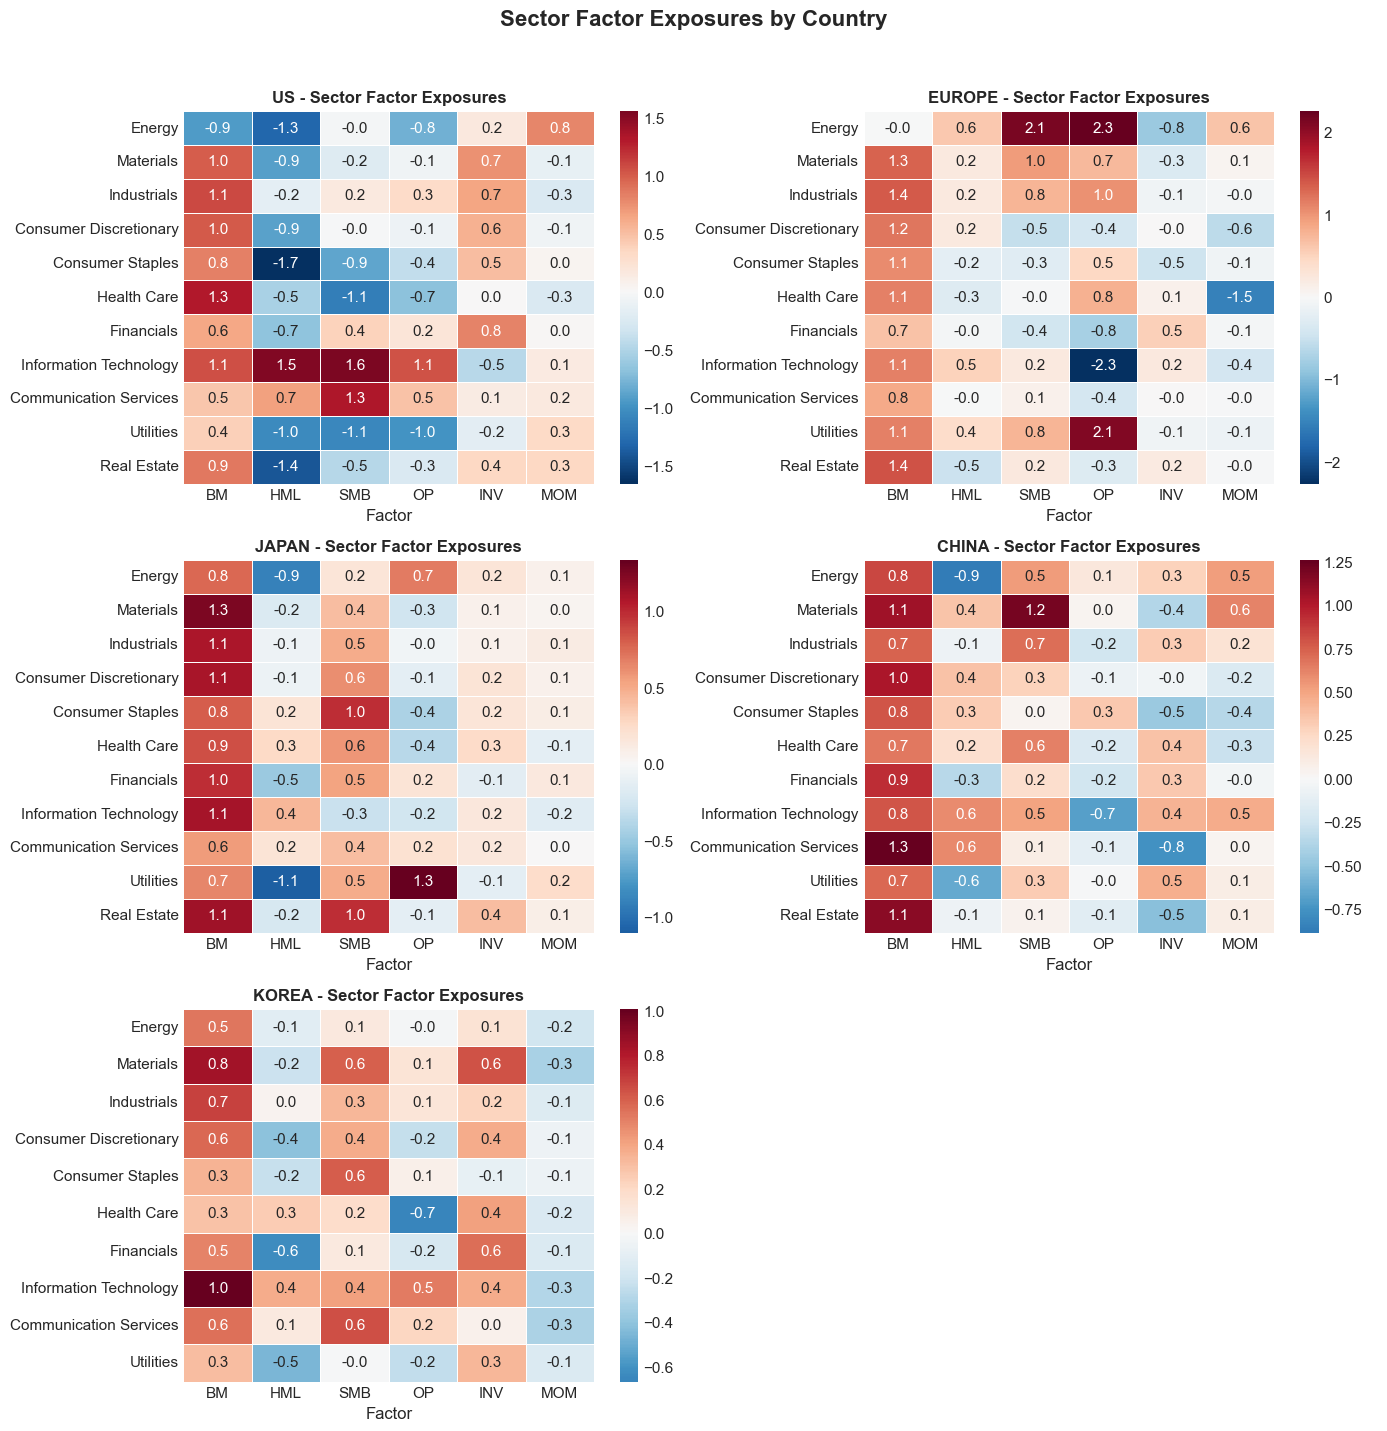

In [15]:
# Sector factor exposure heatmaps
factor_cols = ['beta_bm', 'beta_hml', 'beta_smb', 'beta_op', 'beta_inv', 'beta_mom']

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for idx, country in enumerate(COUNTRIES):
    ax = axes[idx]
    ind_er = data['sector_ER'][country].copy()

    # Get sector names as index
    if 'Sector' in ind_er.columns:
        ind_er = ind_er.set_index('Sector')
    elif 'industry' in ind_er.columns:
        ind_er['Sector'] = ind_er['industry'].astype(str).map(SECTOR_NAMES)
        ind_er = ind_er.set_index('Sector')

    # Get available factor columns
    available_factors = [col for col in factor_cols if col in ind_er.columns]

    if available_factors:
        plot_data = ind_er[available_factors].dropna(how='all')
        plot_data.columns = [c.replace('beta_', '').upper() for c in plot_data.columns]

        sns.heatmap(plot_data, annot=True, fmt='.1f', cmap='RdBu_r',
                    center=0, ax=ax, linewidths=0.5)
        ax.set_title(f'{country.upper()} - Sector Factor Exposures', fontsize=12, fontweight='bold')
        ax.set_xlabel('Factor')
        ax.set_ylabel('')
    else:
        ax.text(0.5, 0.5, 'No factor data available', ha='center', va='center')
        ax.set_title(f'{country.upper()}')

axes[5].axis('off')
plt.suptitle('Sector Factor Exposures by Country', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Sector Expected Returns

In [16]:
# Sector Expected Returns comparison - RAW and NORMALIZED
print("="*90)
print("SECTOR EXPECTED RETURNS BY COUNTRY")
print("="*90)
print("\n⚠️  NOTE: Raw ER values have different scales across countries.")
print("    Use Z-Score for valid cross-country sector comparisons.\n")

# Z-Score normalized sector ERs
sector_zscore_comparison = pd.DataFrame()
for country in COUNTRIES:
    ind_er = data['sector_ER'][country].copy()
    ind_er = ind_er.set_index('Sector')
    sector_zscore_comparison[country.upper()] = ind_er['ER_zscore']

print("\n[2] Z-SCORE NORMALIZED - Comparable (0 = average sector in country)")
print("-"*70)
display(sector_zscore_comparison.style.format('{:.2f}').background_gradient(cmap='RdYlGn', axis=None))

# Cross-country sector analysis
print("\n[4] GLOBAL SECTOR ATTRACTIVENESS (Average Z-Score across countries)")
print("-"*70)
sector_global_strength = sector_zscore_comparison.mean(axis=1).sort_values(ascending=False)
for sector, zscore in sector_global_strength.items():
    strength = "OVERWEIGHT" if zscore > 0.3 else ("UNDERWEIGHT" if zscore < -0.3 else "NEUTRAL")
    bar = "█" * int(abs(zscore) * 10)
    print(f"  {str(sector):25}: {zscore:+.2f} {strength} {bar}")

SECTOR EXPECTED RETURNS BY COUNTRY

⚠️  NOTE: Raw ER values have different scales across countries.
    Use Z-Score for valid cross-country sector comparisons.


[2] Z-SCORE NORMALIZED - Comparable (0 = average sector in country)
----------------------------------------------------------------------


,US,EUROPE,JAPAN,CHINA,KOREA
Sector,,,,,
Energy,-0.29,0.30,0.17,-3.51,0.33
Materials,-0.57,-0.22,0.24,-2.33,0.44
Industrials,-0.26,-0.64,0.14,-1.69,0.75
Consumer Discretionary,-0.40,-0.67,0.08,-2.20,0.99
Consumer Staples,-1.15,-0.82,-0.18,-1.93,0.26
Health Care,-0.34,-0.95,-0.11,-0.50,-0.58
Financials,-0.22,-0.22,0.22,-1.02,0.52
Information Technology,0.29,0.13,0.29,0.22,1.48
Communication Services,-0.08,-0.66,0.13,-1.20,0.22



[4] GLOBAL SECTOR ATTRACTIVENESS (Average Z-Score across countries)
----------------------------------------------------------------------
  Information Technology   : +0.48 OVERWEIGHT ████
  Financials               : -0.14 NEUTRAL █
  Communication Services   : -0.32 UNDERWEIGHT ███
  Industrials              : -0.34 UNDERWEIGHT ███
  Consumer Discretionary   : -0.44 UNDERWEIGHT ████
  Real Estate              : -0.49 UNDERWEIGHT ████
  Materials                : -0.49 UNDERWEIGHT ████
  Health Care              : -0.49 UNDERWEIGHT ████
  Energy                   : -0.60 UNDERWEIGHT ██████
  Utilities                : -0.68 UNDERWEIGHT ██████
  Consumer Staples         : -0.77 UNDERWEIGHT ███████


### Top Equities by country

In [17]:
# Top 10 stocks by Expected Return for each country
print("="*90)
print("TOP 10 STOCKS BY EXPECTED RETURN (Each Country)")
print("="*90)

for country in COUNTRIES:
    print(f"\n{'-'*70}")
    print(f"{country.upper()}")
    print("-"*70)

    top_bot = data['top_bot'][country]
    top_bot['Sector'] = top_bot['sector'].map(lambda x: SECTOR_NAMES[x], na_action='ignore')
    # Get top 10 (highest ER)
    if 'ER' in top_bot.columns:
        top10 = top_bot.nlargest(10, 'ER')[['instrument', 'Name', 'Sector', 'ER', 'Vol', 'Sharpe', 'mktval']]
        top10.columns = ['ISIN', 'Name', 'Sector', 'Expected Return(%)', 'Vol(%)', 'Sharpe(X)', 'Market Cap(Local mn)']
        top10 = top10.style.format({
            'Expected Return(%)': '{:.2f}',
            'Vol(%)': '{:.2f}',
            'Sharpe(X)': '{:.2f}',
            'Market Cap(Local mn)': '{:,.0f}',
        })
        display(top10)

TOP 10 STOCKS BY EXPECTED RETURN (Each Country)

----------------------------------------------------------------------
US
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
1,US24703L2025,Dell Technologies Inc,Info Tech,13.67,18.16,0.75,"243,412"
7,US25402D1028,DigitalOcean Holdings Inc,Info Tech,13.16,23.71,0.56,"11,356"
15,US80004C2008,Sandisk Corp,Info Tech,12.39,26.32,0.47,"200,946"
5,US5951121038,Micron Technology Inc,Info Tech,11.12,19.49,0.57,"1,091,736"
2,US9282981086,Vishay Intertechnology Inc,Info Tech,10.65,16.01,0.67,"6,863"
13,US46125A1007,Intuitive Machines Inc,Industrials,10.24,21.34,0.48,"8,847"
9,US0079031078,Advanced Micro Devices Inc,Info Tech,9.38,18.18,0.52,"836,156"
6,US6792951054,Okta Inc,Info Tech,9.04,15.88,0.57,"21,281"
18,US23804L1035,Datadog Inc,Info Tech,8.66,19.17,0.45,"85,944"
3,US7475251036,Qualcomm Inc,Info Tech,8.59,12.93,0.66,"264,251"



----------------------------------------------------------------------
EUROPE
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
1,NL0000226223,STMicroelectronics NV,Info Tech,6.46,13.53,0.48,"38,724"
14,DE000A2E4K43,Delivery Hero SE,Consumer Disc.,5.89,22.42,0.26,"8,187"
0,DE0006231004,Infineon Technologies AG,Info Tech,5.85,11.72,0.50,"106,412"
3,DE000A0WMPJ6,Aixtron SE,Info Tech,5.85,14.24,0.41,"6,633"
9,IT0005482333,Technoprobe SpA,nan,5.75,17.88,0.32,"8,709"
2,FI0009000681,Nokia Oyj,Info Tech,4.94,11.37,0.43,"66,672"
4,NL0012866412,BE Semiconductor Industries NV,Info Tech,4.88,13.22,0.37,"20,513"
8,CH0030380734,Huber+Suhner AG,nan,3.58,10.95,0.33,"4,380"
5,SE0025158629,Mycronic AB (publ),Info Tech,3.30,9.58,0.34,"4,154"
10,IT0004176001,Prysmian SpA,Industrials,2.94,9.85,0.30,"44,671"



----------------------------------------------------------------------
JAPAN
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
16,JP3236330001,Kioxia Holdings Corp,nan,7.35,27.99,0.26,"12,346,427"
2,JP3888400003,Mitsui Kinzoku Co Ltd,Materials,5.77,17.94,0.32,"2,768,859"
14,JP3148800000,Ibiden Co Ltd,Info Tech,5.70,21.44,0.27,"5,741,476"
17,JP3827200001,Furukawa Electric Co Ltd,Industrials,5.32,20.42,0.26,"3,461,421"
15,JP3811000003,Fujikura Ltd,Industrials,4.32,16.31,0.26,"8,293,891"
5,JP3368000000,Resonac Holdings Corp,Materials,3.98,12.92,0.31,"3,421,684"
3,JP3407400005,Sumitomo Electric Industries Ltd,Consumer Disc.,3.97,12.45,0.32,"9,650,174"
8,JP3571800006,Tokyo Ohka Kogyo Co Ltd,Materials,3.01,10.60,0.28,"1,284,881"
0,JP3695200000,NGK Insulators Ltd,Industrials,2.84,8.35,0.34,"1,786,891"
10,JP3635000007,Toyota Tsusho Corp,Industrials,2.72,9.79,0.28,"4,797,932"



----------------------------------------------------------------------
CHINA
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
7,CNE100001T72,Yangtze Optical Fibre and Cable Joint Stock Ltd Co,nan,7.41,32.44,0.23,"231,679"
1,CNE100002615,Eoptolink Technology Inc Ltd,Info Tech,6.84,21.61,0.32,"563,937"
0,CNE100001CY9,Zhongji Innolight Co Ltd,Info Tech,6.54,18.88,0.35,"926,461"
6,CNE100001XQ1,Suzhou TFC Optical Communication Co Ltd,Info Tech,6.32,27.12,0.23,"189,583"
2,CNE100005VF9,Yuanjie Semiconductor Technology Co Ltd,nan,5.81,19.84,0.29,"90,491"
18,CNE1000055X6,Dosilicon Co Ltd,nan,4.97,25.46,0.20,"39,122"
4,CNE100000N79,Suzhou Dongshan Precision Manufacturing Co Ltd,Info Tech,4.86,20.42,0.24,"265,262"
3,CNE100000F87,Accelink Technologies Co Ltd,Info Tech,4.19,14.70,0.28,"92,555"
8,CNE100006M90,Hua Hong Semiconductor Ltd,nan,4.14,18.24,0.23,"230,003"
5,CNE000000XL5,Shengyi Technology Co Ltd,Info Tech,3.94,16.68,0.24,"166,292"



----------------------------------------------------------------------
KOREA
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
2,KR7402340004,SK Square Co Ltd,Industrials,9.24,21.42,0.43,"110,319,969"
4,KR7009150004,Samsung Electro-Mechanics Co Ltd,Info Tech,8.86,22.86,0.39,"121,858,186"
1,KR7000660001,SK Hynix Inc,Info Tech,8.51,17.51,0.49,"1,304,059,782"
17,KR7307950006,Hyundai Autoever Corp,Info Tech,8.25,27.15,0.30,"4,791,185"
7,KR7000150003,Doosan Corp,Industrials,6.71,18.82,0.36,"17,835,868"
3,KR7034730002,SK Inc,Industrials,6.54,16.74,0.39,"32,542,087"
6,KR7298040007,Hyosung Heavy Industries Corp,Industrials,6.46,17.31,0.37,"17,552,266"
9,KR7353200009,Daeduck Electronics Co Ltd,Info Tech,6.28,18.43,0.34,"6,398,161"
10,KR7006800007,Mirae Asset Securities Co Ltd,Financials,6.25,18.61,0.34,"16,800,464"
11,KR7010120004,LS Electric Co Ltd,Industrials,5.96,18.53,0.32,"18,492,568"


In [18]:
# === LLM Commentary: Sector Analysis ===
_sector_full_txt = "SECTOR ANALYSIS \u2014 Factor Exposures + Expected Returns + Top Equities\n\n"

# Part A: Sector factor betas
_sector_full_txt += "=== PART A: SECTOR FACTOR EXPOSURES (structural betas) ===\n\n"
_beta_cols = ['beta_bm', 'beta_hml', 'beta_smb', 'beta_op', 'beta_inv', 'beta_mom']
for _c in COUNTRIES:
    _ie = data['sector_ER'][_c].copy()
    if 'Sector' in _ie.columns:
        _ie = _ie.set_index('Sector')
    _avail = [col for col in _beta_cols if col in _ie.columns]
    if _avail:
        _exp = _ie[_avail].dropna(how='all').copy()
        _exp.columns = [col.replace('beta_', '').upper() for col in _exp.columns]
        _sector_full_txt += f"{'='*30}\n{_c.upper()}\n{'='*30}\n"
        _sector_full_txt += _exp.round(2).to_string() + "\n\n"

# Part B: Sector expected return Z-scores + 4-week trend
_sector_full_txt += "=== PART B: SECTOR EXPECTED RETURNS (Z-Score + 4-Week Trend) ===\n\n"
_sec_zscore = pd.DataFrame()
for _c in COUNTRIES:
    _ie = data['sector_ER'][_c].copy().set_index('Sector')
    _sec_zscore[_c.upper()] = _ie['ER_zscore']
_sector_full_txt += "Current Z-Score by Country:\n" + _sec_zscore.round(2).to_string() + "\n\n"

_sec_trend = pd.DataFrame()
for _c in COUNTRIES:
    _sts = data['sector_ts'][_c]
    _trends = {}
    for _col in _sts.columns:
        if _col.endswith('_ER') and len(_sts) >= 5:
            _sec_code = _col.replace('_ER', '')
            _sec_name = SECTOR_NAMES.get(_sec_code, _sec_code)
            _chg = float(_sts[_col].iloc[-1]) - float(_sts[_col].iloc[-5])
            _trends[_sec_name] = _chg
    if _trends:
        _sec_trend[_c.upper()] = pd.Series(_trends)
if not _sec_trend.empty:
    _sector_full_txt += "4-Week Sector ER Change by Country:\n"
    _sector_full_txt += _sec_trend.round(4).to_string()
    _sector_full_txt += "\n\nGlobal Average 4-Week Sector ER Change (ranked):\n"
    _global_chg = _sec_trend.mean(axis=1).sort_values(ascending=False)
    for _sec, _v in _global_chg.items():
        _arrow = "↑" if _v > 0 else "↓"
        _sector_full_txt += f"  {str(_sec):28}: {_v:+.4f} {_arrow}\n"

# Part C: Top 20 equities per country
_sector_full_txt += "\n=== PART C: TOP 20 EQUITIES BY EXPECTED RETURN ===\n\n"
for _c in COUNTRIES:
    _tb = data['top_bot'][_c].copy()
    _tb['SectorName'] = _tb['sector'].map(lambda x: SECTOR_NAMES.get(str(x), str(x)))
    if 'ER' in _tb.columns:
        _top20 = _tb.nlargest(20, 'ER')
        _sector_full_txt += f"{'='*40}\n{_c.upper()}\n{'='*40}\n"
        for _, _row in _top20.iterrows():
            _name = str(_row.get('Name', _row.get('instrument', '')))[:30]
            _sec  = str(_row.get('SectorName', ''))[:20]
            _er   = _row.get('ER', 0)
            _sh   = _row.get('Sharpe', 0)
            _sector_full_txt += f"  {_name:30} | {_sec:20} | ER={_er:.2f}% | Sharpe={_sh:.2f}\n"
        _sector_full_txt += "\n"

_sector_prompt = (
"""[Role & Context]\n
당신은 글로벌 헤지펀드의 최고투자책임자(CIO)입니다. 시장(1.4), 팩터(1.5), 섹터 및 탑종목(1.6) 데이터를 최종 합성하여, 보고서의 마무리를 장식할 **"1.6 Sector Analysis & Final Conclusion"**을 작성합니다.\n
\n
[Writing Principles]\n
\n
No Narrative Throat-Clearing: '도입', '근거', '해석' 등의 인위적인 단락 구분을 전면 배제하고, 단도직입적인 헤드라인과 불릿 포인트로 결론만 기술할 것.\n
\n
Cross-Asset Synthesis: 1.5의 상승 팩터(MOM, BM)와 1.6의 섹터 베타/ER, 그리고 탑 20 종목의 정렬 상태를 유기적으로 연결하여 서술할 것.\n
\n
High Density Jargon: 금융 전문 용어(Beta Play, Stock Dispersion, Sector Rotation, Macro Tailwind)를 활용하여 문장의 밀도를 극대화할 것.\n
\n
[Output Structure]\n
\n
1. 팩터-섹터 교차 전술 (Tactical Sector Allocation)\n
[팩터 모멘텀 × 섹터 베타] 수혜 섹터: 1.5의 핵심 팩터(MOM, BM) 가속에 가장 강하게 노출된 국가별 핵심 섹터 지정 및 배분 전략.\n
\n
글로벌 vs 로컬 모멘텀 분리: 4주 ER 기준 글로벌 공통 수혜 섹터(예: 시클리컬)와 특정 국가 고유 현상(예: 한국 IT)을 명확히 이분법으로 분리.\n
\n
2. 탑 20 종목 정합성 및 디스퍼전(Dispersion) 분석\n
섹터 로테이션 방향성과 실제 상위 20개 종목 구성의 일치 여부 진단.\n
\n
특히 미국 시장처럼 섹터 추세와 종목 복수의 흐름이 불일치하는 구간에서의 알파 창출 리포지셔닝 전략(종목 선택 효과 등) 기술.\n
\n
3. 종합 결론: 하이 컨빅션 콜 (High-Conviction Call)\n
[단기 투자 기회 1선]: 가장 데이터 정렬(팩터-섹터-종목)이 완벽한 1가지 전술적 롱(Long) 기회와 구체적 실행 로드맵.\n
\n
[최대 테일 리스크 1선]: 전반적인 포트폴리오를 위협하는 팩터 혼잡(Crowding) 및 동조화 리스크 경고와 헤지 제약 조건."""
)

show_explanation(_sector_full_txt, _sector_prompt, title="1.6 Sector Analysis 종합 해설")


---
### 💬 1.6 Sector Analysis 종합 해설

헤드라인: MOM·BM 가속이 시클리컬·테크 디스퍼전 촉발 — 한국 집중형 Beta‑Play, 미국은 종목별 Stock‑Pick 알파 전략 권고.

1) 팩터‑섹터 교차 전술 (Tactical Sector Allocation)
| 국가 | 핵심 수혜 섹터(우선순위) | 전술 포지셔닝 |
|---|---|---:|
| 한국 | Information Technology, Industrials, Consumer Discretionary | OW (단기 Beta‑Play: 리레이팅 캡처, Strict stops & option hedge) |
| 중국 | Materials, Information Technology, Energy | OW→N (점진적 Entry: 바닥 신호 확인 후 가중) |
| 미국 | Information Technology (Top‑stock 집중) | N(섹터 중립) / Selective OW on top 20 names (Stock‑pick) |
| 유럽 | Energy, Materials | N→OW (단기 Sector‑tilt: 에너지·자원성 수혜) |
| 일본 | Industrials, Utilities | N (중립·모멘텀 체크 후 전개) |

2) 글로벌 vs 로컬 모멘텀 분리 (4주 ER 기준)
- 글로벌 공통 수혜: Energy·Materials·InfoTech — 글로벌 평균 4주 ER 상위에 자리, MOM·BM 가속시 시클리컬·테크 동시 상승 패턴 유효.  
- 로컬 특이점(한국): 한국은 BM·MOM 동시 아웃퍼폼(팩터 가속+섹터 ER 급등)으로 지역적 Beta‑Concentration 발생. 단, HML 과열(고 Z)로 Crowding 리스크 동반.  
- 미국 불일치: 미국 섹터 ER(InfoTech 4주 -0.0476)과 개별 탑종목 ER(상위 20 中 다수 IT, ER 고수준) 간 강한 불일치로 Stock Dispersion 확대 — 섹터 롱보다 종목 선택으로 알파 추구.

3) 탑20 종목 정합성 및 디스퍼전 진단
- 정합성: 한국 탑20(삼성·SK·하이닉스 등)과 섹터 ER(IT·Industrials) 정렬되어 Beta‑Play로 동시 수확 가능.  
- 불일치(알파 기회): 미국 탑20 InfoTech 집중 대비 섹터 ER는 하락 → 종목‑특이 리스크 프리미엄(Dispersion)이 확대되어 Long‑short Stock‑pick 전략(선별 롱/헤지 섹터 베타)으로 높은 알파 기회 제공.  
- 실행 규범: 미국은 섹터 뉴트럴·종목 롱(상위 ER) + 광역 IT‑ETF 숏 또는 베타 헤지로 Net‑sector exposure 제로 유지.

4) 종합 결론: 하이 컨빅션 콜 및 테일 리스크
- 단기 투자 기회 1선(High‑Conviction Long): Korea — Tactical Long on Korean IT + Industrials (Beta‑Play). 실행 로드맵: 포지션 규모 제한(포트폴리오 대비 ≤10%), 분할 진입(3트랜치, 모멘텀 유지시 가중), 트레일링 스탑(모멘텀 역전 시 즉시 50% 축소), 옵션 보호(풋스프레드) 병행.  
- 최대 테일 리스크 1선: Korea 팩터 혼잡(Crowding) — HML·BM·MOM 동시 고Z로 인한 집단 회수(Sharpe‑pullback) 리스크. 헤지 제약 조건: 한국 집중 익스포저가 전체 포트폴리오 VaR의 25% 초과 시 즉시 리덕션, 글로벌 SMB 숏(분산효과 회복용) 및 현금/단기국채로 방어 비중 확충 권고.

---

In [21]:
!jupyter nbconvert --to html C:\Users\NHWM\PycharmProjects\Factor_Research\output\0.export\market_research.ipynb --no-input

[NbConvertApp] Converting notebook C:\Users\NHWM\PycharmProjects\Factor_Research\output\0.export\market_research.ipynb to html
[NbConvertApp] ERROR | Notebook JSON is invalid: Additional properties are not allowed ('jetTransient' was unexpected)

Failed validating 'additionalProperties' in display_data:

On instance['cells'][9]['outputs'][0]:
{'data': {'image/png': 'iVBORw0KGgoAAAANSUhEUgAABWoAAAWXCAYAAADeQk21AAAAOnRFWHRTb2Z0d2Fy...',
          'text/plain': '<Figure size 1400x1400 with 6 Axes>'},
 'jetTransient': {'display_id': None},
 'metadata': {},
 'output_type': 'display_data'}
[NbConvertApp] WARNING | Alternative text is missing on 5 image(s).
[NbConvertApp] Writing 1607429 bytes to C:\Users\NHWM\PycharmProjects\Factor_Research\output\0.export\market_research.html


In [22]:
!pandoc C:\Users\NHWM\PycharmProjects\Factor_Research\output\0.export\market_research.html -o C:\Users\NHWM\PycharmProjects\Factor_Research\output\0.export\market_research.docx